# 06 CLIP image search over the whole catalogue
In notebook 05 I tested pictures on only 708 products. Here I downloaded the first picture of almost every product, turned them all into CLIP vectors, and searched the whole catalogue. I scored the results with my ratings, next to the text methods. CLIP was used as it is, with no training. Nothing here uses the 20 locked final products.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
plt.rcParams.update(
    {"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREEN = "#4c78a8", "#54a24b"
pd.set_option("display.width", 170)

results = root / "results"
download = json.loads((results / "image_download_summary.json").read_text(encoding="utf-8"))
speed = json.loads((results / "image_embedding_speed_all.json").read_text(encoding="utf-8"))
coverage = json.loads((results / "dev_full_image_search_coverage.json").read_text(encoding="utf-8"))
board = pd.read_csv(results / "dev_full_image_scoreboard.csv").set_index("method")
pairs = pd.read_csv(results / "dev_full_image_pairwise.csv")
print("loaded the saved results")

loaded the saved results


## 1. The pictures
I downloaded the first picture of every product except the 20 locked ones, one request at a time and at most 4 per second. The pictures stay on my computer and are not in Git.

In [2]:
print(f"links to cover: {download['links_to_cover']:,}")
print(f"downloaded: {download['downloaded']:,} ({download['megabytes']:.0f} MB)")
print(
    f"failed: {sum(download['failed'].values())} ({', '.join(f'{k}: {v}' for k, v in download['failed'].items())})"
)
print(f"locked products included: {download['locked_products_included']}")

links to cover: 29,241
downloaded: 29,107 (763 MB)
failed: 134 (http_404: 134)
locked products included: 0


### What this shows
Almost every picture downloaded. The 134 that failed are links that no longer exist (error 404). None of the pictures belong to the locked products.

## 2. Pictures shared by several products
231 of the pictures are used by two or more products. In notebook 05 I feared many of them were size charts, which would make unrelated products look alike. I looked at all 231 on contact sheets.

- 229 are normal product photos. They are the same item listed more than once, for example in different sizes or colours.
- 2 are not product photos: a shop logo and a sewing-pattern drawing. I left those two out of the image search.
- I found no size charts.

So the plan to filter size charts was not needed. Instead, the search shows **one copy of each item**. Two results count as the same item when they use the same picture, or when their picture vectors are almost identical. Copies of the product I am searching for are not shown, because they are not new recommendations. Every method gets the same rule, so the comparison stays fair.

## 3. Turning all pictures into vectors
Each picture becomes 512 numbers with CLIP. Pictures that look alike get vectors that are close together.

In [3]:
display(
    pd.DataFrame(
        {
            "pictures": [f"{speed['vectors']:,}"],
            "numbers per picture": [speed["dimensions"]],
            "failed to open": [speed["failed_to_open"]],
            "minutes": [speed["minutes"]],
        },
        index=["CLIP"],
    )
)

,pictures,numbers per picture,failed to open,minutes
CLIP,"29,107",512,0,7.6


### What this shows
All pictures could be opened. Turning 29,107 pictures into vectors took less than 8 minutes on my laptop.

## 4. Searching
For each of my 30 development products, CLIP found the 10 most similar products among all the pictures. Results that I had already rated kept their rating. I rated the rest myself without seeing which method found them, so every method is scored with the same ratings.

In [4]:
print(f"results: {coverage['results_total']} (10 for each of {coverage['dev_products']} products)")
print(f"already rated before: {coverage['already_rated']}")
print(f"rated now: {coverage['new_results_to_rate']}")
print(
    f"copies left out: {coverage['dropped_copy_of_query']} of the searched product, "
    f"{coverage['dropped_copy_of_result']} of another result"
)

results: 300 (10 for each of 30 products)
already rated before: 44
rated now: 256
copies left out: 2 of the searched product, 13 of another result


## 5. Scoreboard
Each method returns its 10 most similar products for the 30 development products. **nDCG@10** gives more credit to good results near the top. **Precision@10** is the share of the top 10 that I rated 1 or 2.

In [5]:
labels = {
    "image_clip_all": "CLIP, whole catalogue (pictures)",
    "baseline": "Text + attributes (my baseline)",
    "image_clip_708": "CLIP, first 708 pictures only",
    "title_only": "Title only",
    "attributes_only": "Attributes only",
}
table = pd.DataFrame(
    {
        "Method": [labels[m] for m in labels],
        "nDCG@10": [round(board.loc[m, "ndcg_at_10"], 3) for m in labels],
        "Precision@10": [round(board.loc[m, "precision_at_10"], 2) for m in labels],
    }
).set_index("Method")
display(table)

,nDCG@10,Precision@10
Method,,
"CLIP, whole catalogue (pictures)",0.757,0.85
Text + attributes (my baseline),0.644,0.74
"CLIP, first 708 pictures only",0.648,0.74
Title only,0.507,0.54
Attributes only,0.427,0.62


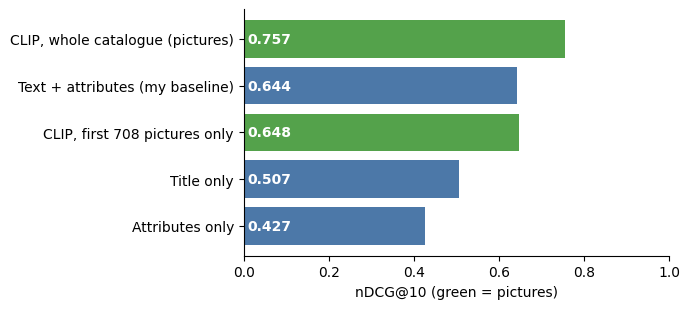

In [6]:
fig, ax = plt.subplots()
names = list(labels)[::-1]
values = [board.loc[m, "ndcg_at_10"] for m in names]
ax.barh(
    [labels[m] for m in names],
    values,
    color=[GREEN if m.startswith("image") else BLUE for m in names],
)
for i, v in enumerate(values):
    ax.text(0.01, i, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 (green = pictures)")
plt.tight_layout()
plt.show()

### What this shows
CLIP over the whole catalogue has the highest score. The text baseline is second, and title only and attributes only are lower. CLIP over only 708 pictures scored about the same as the baseline, so searching the whole catalogue made it better.

## 6. Are the differences real or luck?
For each pair of methods, I compared the nDCG@10 on the same products. If the difference could come from the choice of products, I call it luck.

In [7]:
wanted = [
    ("image_clip_all", "baseline"),
    ("image_clip_all", "title_only"),
    ("image_clip_all", "attributes_only"),
    ("image_clip_all", "image_clip_708"),
]
rows = []
for a, b in wanted:
    hit = pairs[
        ((pairs["first"] == a) & (pairs["second"] == b))
        | ((pairs["first"] == b) & (pairs["second"] == a))
    ].iloc[0]
    sign = 1 if hit["first"] == a else -1
    rows.append(
        {
            "comparison": f"{labels[a]} minus {labels[b]}",
            "difference": f"{sign * hit['ndcg_difference']:+.3f}",
            "verdict": "real" if hit["difference_is_real"] else "could be luck",
        }
    )
display(pd.DataFrame(rows).set_index("comparison"))

,difference,verdict
comparison,,
"CLIP, whole catalogue (pictures) minus Text + attributes (my baseline)",+0.113,could be luck
"CLIP, whole catalogue (pictures) minus Title only",+0.250,real
"CLIP, whole catalogue (pictures) minus Attributes only",+0.329,real
"CLIP, whole catalogue (pictures) minus CLIP, first 708 pictures only",+0.108,real


### What this shows
CLIP is clearly better than title only and attributes only, and clearly better than CLIP on the small set. CLIP against the text baseline could be luck with 30 products, so I do not call a winner there.

## 7. Recorded in MLflow
All five runs are saved in MLflow with their settings and scores. This is MLflow's comparison page:

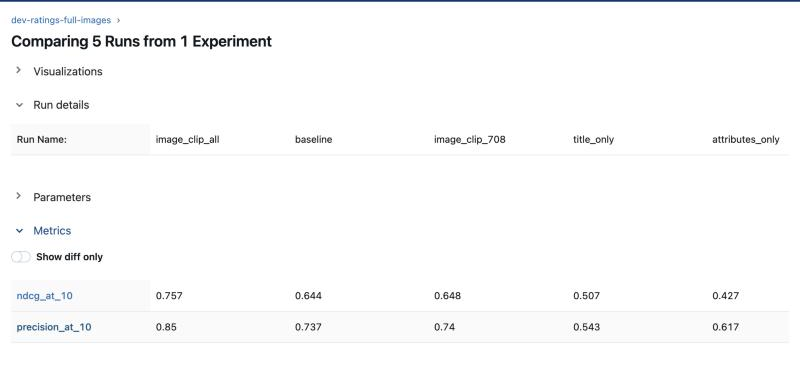

In [8]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_full_image_runs.png", width=900)

## 8. Conclusion

**What I wanted to know:** do product pictures help me find similar products? This time I searched the whole catalogue.

**What I did.** I took about 29,000 product pictures and turned each one into a list of numbers with CLIP. Pictures that look alike get numbers that are close together. For my 30 test products I found the 10 most similar items. I rated the new results myself, without knowing which method found them. I used one set of my ratings to check every method, so the comparison is fair, and I show only one copy of each item.

| Method | nDCG@10 | Precision@10 |
|---|---|---|
| CLIP, whole catalogue (pictures) | 0.757 | 0.85 |
| Text and attributes (my baseline) | 0.644 | 0.74 |
| CLIP, first 708 pictures only | 0.648 | 0.74 |
| Title only | 0.507 | 0.54 |
| Attributes only | 0.427 | 0.62 |

Precision@10 is how many of the top 10 I rated 1 or 2.

**What I found**

- CLIP beats title only and attributes only. The gap is real.
- CLIP is ahead of my text baseline too, but with only 30 products I can't be sure it is really better.
- When CLIP searched the whole catalogue, it did better than when it searched only 708 pictures.
- Pictures and text both find good matches on their own, so I want to try using them together.

**What I can't say yet**

- I tested only 30 products, and I was the only person rating.
- I haven't touched my 20 final test products.

**What I do next.** I will mix text, CLIP and attributes into one hybrid search, then make it fast with an index.